# Research Paper: Predictive Forecasting of Care Load and Placement Demand

This notebook contains the written research paper, independent empirical analysis, five KPI calculations where supported by actual prediction files, and DOCX/PDF export. Run all cells from top to bottom.

## Package requirements

The notebook-creation cell checks for and installs the required packages. If a package is installed while this notebook is open, restart the kernel and run all cells from the beginning.

# Predictive Forecasting of Care Load and Placement Demand

**Research Paper**

**Study period:** Determined from the cleaned project dataset.

**Research focus:** Forecasting care load, evaluating predictive performance, quantifying uncertainty, and examining operational scenarios.

## Abstract

This study investigates predictive forecasting approaches for monitoring care load and supporting placement-demand planning. The analysis uses the project's cleaned operational dataset, containing observations of children apprehended and placed in Customs and Border Protection (CBP) custody, children remaining in CBP custody, transfers out of CBP custody, children in the care of the Department of Health and Human Services (HHS), and children discharged from HHS care.

The principal forecasting target is the number of children in HHS care. The research examines historical patterns, forecasting model outputs, validation and test predictions, five forecast-accuracy measures, prediction intervals, and scenario-based capacity outputs.

The empirical results are generated from the actual dataset and saved project outputs when this notebook is executed. The study does not assume model scores, scenario outcomes, or uncertainty estimates that are not supported by available evidence. Particular attention is given to missing observations and the distinction between stock and flow variables.

The findings are intended to support evidence-informed monitoring and capacity planning. Forecasts are treated as decision-support information rather than guaranteed future outcomes.

**Keywords:** care demand, time-series forecasting, predictive modelling, child welfare, capacity planning, prediction intervals.


## 1. Introduction and Problem Statement

### 1.1 Background

Organisations responsible for child care and placement must plan resources in an environment where caseloads can change over time. Changes in the number of children requiring care may create pressure on placement availability, staffing, and operational resources.

Historical observations can provide information about changes in care demand. Forecasting methods use this information to estimate possible future caseloads and support planning.

### 1.2 Research problem

The central research problem is the difficulty of estimating future care load accurately while accounting for uncertainty and incomplete observations.

A model may perform well on historical training data but fail to generalise to future observations. Point forecasts also provide limited information about the range of plausible future outcomes.

The dataset contains both stock variables and flow variables. Current numbers in custody or care are stock measures, whereas apprehensions, transfers, and discharges are flow measures. These variables must not be treated as interchangeable.

### 1.3 Research aim

The aim is to evaluate forecasting approaches for estimating future HHS care load and assess how forecast accuracy, uncertainty, and scenario analysis can support capacity planning.

### 1.4 Research objectives

1. Examine the cleaned dataset and its data-quality characteristics.
2. Document the forecasting approaches implemented in the project.
3. Examine the validation and test strategy.
4. Compare forecasting performance using five KPIs.
5. Analyse predictive uncertainty and available prediction intervals.
6. Examine scenario forecasts and capacity-related outputs.
7. Discuss findings, limitations, and operational implications.
8. Produce a reproducible research paper in DOCX and PDF formats.

### 1.5 Research questions

- What historical patterns are visible in the HHS care caseload?
- How accurately do the implemented models forecast future observations?
- How do the models compare using five evaluation measures?
- What information do prediction intervals provide?
- What do the available scenarios indicate about possible capacity pressure?
- What limitations affect the interpretation of the forecasts?


## 2. Literature Review

### 2.1 Time-series forecasting

Time-series forecasting uses observations ordered in time to estimate future values. Methods range from simple benchmarks to statistical and machine-learning approaches. A sound forecasting workflow includes data exploration, benchmark comparisons, model selection, and evaluation on observations not used for fitting.

### 2.2 Forecast validation

Forecast evaluation should reflect the intended real-world use of a model. For time-dependent data, chronological validation is important because future observations should not influence training.

Tashman (2000) reviews out-of-sample testing approaches and their role in evaluating forecasting accuracy.

### 2.3 Machine learning in forecasting

Machine-learning methods can represent nonlinear patterns and interactions. Their effectiveness depends on data quality, feature construction, model complexity, and validation design.

### 2.4 Forecast uncertainty

Point forecasts do not fully represent the uncertainty associated with future outcomes. Prediction intervals provide a range of plausible values under the assumptions of a forecasting method.

Gneiting and Raftery (2007) discuss probabilistic forecasting and the evaluation of predictive distributions.

### 2.5 Research contribution

This project integrates historical monitoring, predictive forecasting, uncertainty analysis, and scenario-based capacity assessment using operational care-load data. Its contribution is an evidence-led assessment of the available forecasting outputs and their limitations.


## 3. Dataset and Variables

### 3.1 Dataset source

The cleaned dataset is loaded from:

`data/processed/cleaned_care_data.csv`

The notebook independently loads this file from the project directory.

### 3.2 Dataset variables

| Variable | Description | Type |
|---|---|---|
| date | Observation date | Date |
| children_apprehended_and_placed_in_cbp_custody | Children apprehended and placed in CBP custody | Flow |
| children_in_cbp_custody | Children in CBP custody | Stock |
| children_transferred_out_of_cbp_custody | Children transferred out of CBP custody | Flow |
| children_in_hhs_care | Children in HHS care | Stock; primary target |
| children_discharged_from_hhs_care | Children discharged from HHS care | Flow |

The actual dataset columns are checked during execution.

### 3.3 Primary target

The primary target variable is `children_in_hhs_care`. It represents the recorded HHS care caseload.

### 3.4 Data quality

Missing dates do not automatically indicate zero activity. Missing stock observations are not automatically interpolated or replaced with zero.

The analysis reports missing values, date coverage, and descriptive statistics before interpreting the forecasting outputs.


## 4. Research Methodology

### 4.1 Research design

The research follows a quantitative retrospective forecasting design. Historical observations are examined and saved model outputs are evaluated.

### 4.2 Data preparation

The cleaned dataset is loaded, dates are parsed, and records are sorted chronologically. Numeric variables are inspected. Original observations are retained for descriptive reporting.

### 4.3 Forecasting horizons

The project considers horizons of 1, 7, 14, and 30 days. The available prediction files are inspected to establish which horizons have actual saved results.

### 4.4 Forecast accuracy

The following five measures are calculated when actual and predicted observations are available.

**Mean Absolute Error**

\[
MAE = \frac{1}{n}\sum_{t=1}^{n}|y_t-\hat{y}_t|
\]

**Root Mean Squared Error**

\[
RMSE = \sqrt{\frac{1}{n}\sum_{t=1}^{n}(y_t-\hat{y}_t)^2}
\]

**Mean Absolute Percentage Error**

\[
MAPE = \frac{100}{n}\sum_{t=1}^{n}
\left|\frac{y_t-\hat{y}_t}{y_t}\right|
\]

Zero actual values are excluded.

**Symmetric Mean Absolute Percentage Error**

\[
sMAPE = \frac{100}{n}\sum_{t=1}^{n}
\frac{2|y_t-\hat{y}_t|}{|y_t|+|\hat{y}_t|}
\]

Zero denominators are excluded.

**Coefficient of Determination**

\[
R^2 = 1-\frac{\sum_{t=1}^{n}(y_t-\hat{y}_t)^2}
{\sum_{t=1}^{n}(y_t-\bar{y})^2}
\]

Lower MAE, RMSE, MAPE, and sMAPE indicate smaller errors. Higher R² indicates better performance relative to the mean benchmark.

### 4.5 Uncertainty analysis

Prediction intervals are examined using saved interval outputs. Interval bounds, widths, and empirical coverage are reported only where the required fields are available.

### 4.6 Scenario analysis

Scenario outputs are examined as conditional projections based on their saved assumptions. They are not interpreted as causal estimates.

### 4.7 Reproducibility

The notebook independently loads the dataset and output files so that the analysis can be repeated when project outputs are updated.


## 5. Forecasting Models

### 5.1 Baseline models

Baseline models provide reference predictions against which more complex approaches can be evaluated. The exact baseline method is identified from project implementation and saved outputs.

### 5.2 Statistical forecasting

Statistical forecasting approaches use historical time-series structure to estimate future values. The exact implemented methods must be confirmed from the project artefacts.

### 5.3 Machine-learning forecasting

Machine-learning methods use engineered features and fitted predictive relationships. Recursive forecasting may use earlier predictions to generate later forecast steps, potentially allowing errors to accumulate.

### 5.4 Combined forecasting

Combined forecasting may integrate predictions from multiple models. Its weighting or combination method must be verified from the actual implementation.

### 5.5 Comparative evaluation

All model comparisons should use consistent target definitions, evaluation periods, and forecast horizons. A complex model should demonstrate measurable improvement over a credible baseline.


## 6. Validation Strategy

### 6.1 Chronological splitting

Training observations should precede validation and test observations. This reflects the real forecasting situation.

### 6.2 Validation data

Validation data can support model selection and tuning. The notebook reports the actual saved validation evidence.

### 6.3 Test data

Test data should provide an independent evaluation of predictive performance where a separate test partition was used.

### 6.4 Walk-forward validation

Where walk-forward outputs exist, they are examined as evidence of sequential prediction. The exact implementation determines whether the model was refitted at each forecast origin.

### 6.5 Data leakage

Future observations must not influence training features or model fitting. Model comparisons are interpreted in light of the actual saved validation design.


## 7. Model Results

The empirical results are generated from available project prediction files.

The analysis identifies files containing actual and predicted values, calculates the five KPIs where possible, and reports the source file and identifiable evaluation partition.

A model is not declared the best-performing model unless its results can be compared fairly with other models on comparable observations.


## 8. Five Key Performance Indicators

The five KPIs are:

1. MAE: average absolute forecast error.
2. RMSE: square root of average squared forecast error.
3. MAPE: average absolute percentage error.
4. sMAPE: symmetric percentage error.
5. R²: performance relative to the observed mean benchmark.

Percentage-based metrics require caution when actual values are zero or close to zero. MAE and RMSE retain the target's original units. R² may be negative and should not be interpreted as a percentage accuracy score.

The notebook calculates these measures from matched actual and predicted values. It does not invent scores when the necessary columns are unavailable.


## 9. Uncertainty Analysis

Prediction uncertainty is important because future care demand cannot be known with certainty.

The analysis examines available lower and upper prediction bounds, interval widths, and empirical coverage where actual values can be matched to interval predictions.

A nominal interval level does not guarantee that the realised outcome will fall inside the interval. Coverage and interval width should be reviewed as new observations become available.


## 10. Scenario Analysis

Scenario analysis explores possible future conditions under alternative assumptions.

Available scenario files are examined for daily forecasts, summaries, peak-load estimates, capacity-breach probabilities, and resource-pressure measures.

All scenario results are conditional on the assumptions and calculations used to generate them. They should not be interpreted as causal estimates or guaranteed outcomes.


## 11. Discussion

The findings are interpreted using the actual dataset profile, calculated KPIs, uncertainty outputs, and scenario results.

Forecast accuracy should be considered alongside forecast stability, uncertainty, data quality, and operational relevance.

Forecasts can support monitoring and capacity-planning discussions, but they should be combined with current operational information and professional judgement.


## 12. Limitations

1. Conclusions are limited to the dataset's observed coverage.
2. Missing reporting dates must not be treated automatically as zero.
3. Stock and flow variables represent different operational concepts.
4. Forecast uncertainty generally increases with the forecast horizon.
5. Model performance depends on training data, features, and model specification.
6. Model rankings are unreliable when evaluation samples differ.
7. Prediction intervals depend on their construction method.
8. Scenario outputs depend on assumptions and simplified operational relationships.
9. The dataset may not contain every factor affecting placement availability.
10. Predictive associations do not establish causation.

Forecasts should therefore be treated as decision-support evidence rather than automatic operational instructions.


## 13. Conclusions and Recommendations

### 13.1 Conclusion

This research evaluates predictive forecasting of care load and placement demand using the project's cleaned operational dataset and saved forecasting outputs.

The principal target is the HHS care caseload. The analysis considers historical trends, model predictions, five accuracy measures, predictive uncertainty, and scenario-based capacity outputs.

Numerical conclusions are generated from the actual project files during execution. This ensures that reported results are evidence-based.

### 13.2 Recommendations

1. Maintain a documented data-quality process.
2. Preserve the distinction between stock and flow variables.
3. Do not automatically replace missing reporting dates with zero.
4. Evaluate models using chronological validation and test observations.
5. Report all five KPIs together.
6. Review prediction interval coverage and width.
7. Document all scenario assumptions.
8. Monitor forecast errors as new observations become available.
9. Combine forecast evidence with operational knowledge.
10. Retain reproducible records of datasets, models, and evaluation results.

### 13.3 Future research

Future research could investigate additional explanatory variables, alternative probabilistic forecasting methods, longer back-testing periods, and validation with operational stakeholders.


## References

Gneiting, T., & Raftery, A. E. (2007). Strictly proper scoring rules, prediction, and estimation. *Journal of the American Statistical Association, 102*(477), 359–378. https://doi.org/10.1198/016214506000001437

Hyndman, R. J., & Athanasopoulos, G. (2021). *Forecasting: Principles and Practice* (3rd ed.). OTexts. https://otexts.com/fpp3/

Makridakis, S., Spiliotis, E., & Assimakopoulos, V. (2018). The M4 Competition: Results, findings, conclusion and way forward. *International Journal of Forecasting, 34*(4), 802–808. https://doi.org/10.1016/j.ijforecast.2018.06.001

Tashman, L. J. (2000). Out-of-sample tests of forecasting accuracy: An analysis and review. *International Journal of Forecasting, 16*(4), 437–450. https://doi.org/10.1016/S0169-2070(00)00065-0


## Empirical analysis and results

DATASET PROFILE
Shape: (720, 6)
Date range: 2023-01-12 00:00:00 to 2025-12-21 00:00:00

Data types:


,data_type
date,datetime64[ns]
children_apprehended_and_placed_in_cbp_custody,int64
children_in_cbp_custody,int64
children_transferred_out_of_cbp_custody,int64
children_in_hhs_care,int64
children_discharged_from_hhs_care,int64



Missing values:


,missing_count
date,0
children_apprehended_and_placed_in_cbp_custody,0
children_in_cbp_custody,0
children_transferred_out_of_cbp_custody,0
children_in_hhs_care,0
children_discharged_from_hhs_care,0



Descriptive statistics:


,count,mean,min,25%,50%,75%,max,std
date,720,2024-07-06 05:29:59.999999744,2023-01-12 00:00:00,2023-10-16 18:00:00,2024-07-05 12:00:00,2025-03-25 06:00:00,2025-12-21 00:00:00,NaN
children_apprehended_and_placed_in_cbp_custody,720.0,93.523611,0.0,12.0,99.0,147.25,333.0,72.646625
children_in_cbp_custody,720.0,171.494444,7.0,36.0,193.0,263.25,531.0,126.354965
children_transferred_out_of_cbp_custody,720.0,128.668056,0.0,14.0,157.0,199.25,440.0,97.322012
children_in_hhs_care,720.0,6061.275,1972.0,2467.75,6406.5,8010.25,11516.0,2833.070109
children_discharged_from_hhs_care,720.0,173.406944,0.0,19.75,181.0,267.0,505.0,125.702841


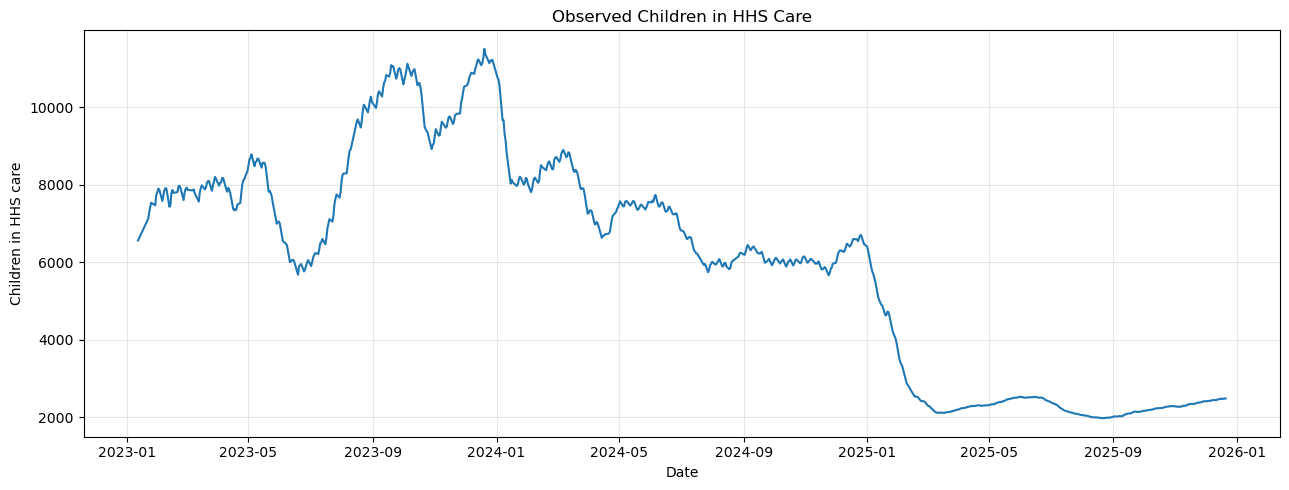


PROJECT OUTPUT FILES
outputs\annual_mean_patterns.csv
outputs\annual_observation_counts.csv
outputs\annual_observed_flow_sums.csv
outputs\arima_candidate_parameters.csv
outputs\baseline_predictions.csv
outputs\baseline_test_metrics.csv
outputs\baseline_validation_metrics.csv
outputs\best_baseline_models.csv
outputs\best_model_summary.csv
outputs\best_statistical_models.csv
outputs\central_tendency_and_dispersion.csv
outputs\chronological_split_summary.csv
outputs\combined_model_predictions.csv
outputs\custody_transfer_relationships.csv
outputs\daily_changes.csv
outputs\daily_percentage_changes.csv
outputs\deployment\complete_deployment_checklist.csv
outputs\deployment\dashboard_performance_results.csv
outputs\deployment\dashboard_performance_summary.csv
outputs\deployment\data_refresh_comparison_details.csv
outputs\deployment\data_refresh_exception_details.csv
outputs\deployment\data_refresh_final_verification.csv
outputs\deployment\data_refresh_verification_checks.csv
outputs\deploym


PREDICTION FILE AUDIT


,file,status
0,outputs\annual_mean_patterns.csv,No confidently identifiable actual/predicted c...
1,outputs\annual_observation_counts.csv,No confidently identifiable actual/predicted c...
2,outputs\annual_observed_flow_sums.csv,No confidently identifiable actual/predicted c...
3,outputs\arima_candidate_parameters.csv,No confidently identifiable actual/predicted c...
4,outputs\baseline_predictions.csv,Metrics calculated
...,...,...
200,outputs\validation_predictions.csv,Metrics calculated
201,outputs\variable_correlations.csv,No confidently identifiable actual/predicted c...
202,outputs\walk_forward_predictions.csv,Metrics calculated
203,outputs\weekly_observation_counts.csv,No confidently identifiable actual/predicted c...



FIVE KPI RESULTS


,file,partition,actual_column,predicted_column,n,MAE,RMSE,MAPE_percent,sMAPE_percent,R2
0,outputs\baseline_predictions.csv,Not identified,Actual,Predicted,3900,404.215602,807.706571,15.890016,12.638823,-0.875254
1,outputs\combined_model_predictions.csv,Not identified,Actual,Predicted,32300,1335.081774,2207.642920,56.764663,32.527973,-8.449971
2,outputs\evaluation\prediction_intervals.csv,Not identified,Actual,Predicted,2730,1365.752740,2306.380938,62.861639,34.150336,-222.090021
3,outputs\evaluation\test_predictions.csv,Test,Actual,Predicted,2730,1365.752740,2306.380938,62.861639,34.150336,-222.090021
4,outputs\evaluation\validation_predictions.csv,Validation,Actual,Predicted,3302,1426.817262,2245.056780,56.944907,33.757509,-5.513217
5,outputs\machine_learning_recursive_predictions...,Not identified,Actual,Predicted,416,3470.051321,3567.486872,152.124213,83.348999,-16.324095
6,outputs\machine_learning_test_errors.csv,Test,Actual,Predicted,1040,4078.515208,4093.480641,187.643647,96.459258,-613.997561
7,outputs\machine_learning_test_predictions.csv,Test,Actual,Predicted,1040,4078.515208,4093.480641,187.643647,96.459258,-613.997561
8,outputs\machine_learning_validation_errors.csv,Validation,Actual,Predicted,1040,3696.764884,3932.895694,151.584692,80.312152,-12.044224
9,outputs\machine_learning_validation_prediction...,Validation,Actual,Predicted,1040,3696.764884,3932.895694,151.584692,80.312152,-12.044224



UNCERTAINTY OUTPUTS

FILE: outputs\evaluation\prediction_intervals.csv
Shape: (2730, 34)
Columns: ['model', 'actual', 'predicted', 'actual_target_date', 'forecast_origin', 'horizon', 'partition', 'forecasting_method', 'model_family', 'residual', 'absolute_error', 'squared_error', 'absolute_actual', 'absolute_percentage_error', 'period_type', 'rolling_7_observation_mean', 'Actual', 'Predicted', 'Partition', 'Model', 'Horizon', 'Date', 'Source_File', 'Residual', 'Lower_80', 'Upper_80', 'Lower_95', 'Upper_95', 'Width_80', 'Width_95', 'Covered_80', 'Covered_95', 'Month', 'Period_Type']


... (59 outputs left out)

,Scenario,Simulation,Horizon,Simulated_HHS_Care,Simulated_CBP_Custody,Simulated_Total_Population,Capacity_Breach
0,Low_Demand,0,1,2481.300000,13.600000,2494.900000,NaN
1,Low_Demand,0,7,2446.100000,0.000000,2446.100000,NaN
2,Low_Demand,0,14,2402.700000,1.800000,2404.500000,NaN
3,Low_Demand,0,30,2381.166667,0.000000,2381.166667,NaN
4,Low_Demand,1,1,2484.300000,6.600000,2490.900000,NaN
5,Low_Demand,1,7,2464.350000,0.000000,2464.350000,NaN
6,Low_Demand,1,14,2451.783333,0.000000,2451.783333,NaN
7,Low_Demand,1,30,2426.250000,0.000000,2426.250000,NaN
8,Low_Demand,2,1,2484.300000,19.600000,2503.900000,NaN
9,Low_Demand,2,7,2498.100000,0.933333,2499.033333,NaN



FILE: outputs\scenario_analysis\scenario_uncertainty.csv
Shape: (12, 12)
Columns: ['Scenario', 'Horizon', 'HHS_Mean', 'HHS_Lower_80', 'HHS_Upper_80', 'HHS_Lower_95', 'HHS_Upper_95', 'HHS_Uncertainty_Width_80', 'HHS_Uncertainty_Width_95', 'CBP_Mean', 'CBP_Lower_95', 'CBP_Upper_95']


,Scenario,Horizon,HHS_Mean,HHS_Lower_80,HHS_Upper_80,HHS_Lower_95,HHS_Upper_95,HHS_Uncertainty_Width_80,HHS_Uncertainty_Width_95,CBP_Mean,CBP_Lower_95,CBP_Upper_95
0,Baseline,1,2483.931833,2478.000000,2490.100000,2474.000000,2495.000000,12.100000,21.000000,15.791333,7.0,27.000000
1,Baseline,7,2483.173000,2465.333333,2500.666667,2455.987500,2508.593750,35.333333,52.606250,7.262000,0.0,30.000000
2,Baseline,14,2482.189333,2457.483333,2505.683333,2445.991667,2516.585417,48.200000,70.593750,4.322583,0.0,24.683333
3,Baseline,30,2479.779917,2444.558333,2516.350000,2427.325000,2537.339583,71.791667,110.014583,3.433167,0.0,19.341667
4,High_Demand,1,2485.631967,2479.700000,2491.700000,2475.700000,2496.700000,12.000000,21.000000,16.160000,7.4,27.400000
5,High_Demand,7,2494.559250,2478.233333,2510.925000,2469.062500,2520.241667,32.691667,51.179167,9.086083,0.0,30.800000
6,High_Demand,14,2506.352867,2483.405000,2529.491667,2471.230833,2541.469167,46.086667,70.238333,5.819833,0.0,27.671250
7,High_Demand,30,2531.422650,2497.320000,2566.046667,2480.242083,2583.687083,68.726667,103.445000,4.758967,0.0,25.605000
8,Low_Demand,1,2482.059917,2476.300000,2488.300000,2472.300000,2493.300000,12.000000,21.000000,15.429150,6.6,26.600000
9,Low_Demand,7,2470.769833,2454.091667,2488.133333,2446.100000,2496.114583,34.041667,50.014583,5.566517,0.0,26.070000



EVIDENCE AUDIT COMPLETE


In [1]:

# Load the cleaned dataset and inspect all available project evidence

from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = Path(r"C:\Users\hp\Predictive Forecasting of Care Load & Placement Demand")
DATA_PATH = PROJECT_ROOT / "data" / "processed" / "cleaned_care_data.csv"
OUTPUT_ROOT = PROJECT_ROOT / "outputs"

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH}")

df = pd.read_csv(DATA_PATH)

if "date" in df.columns:
    df["date"] = pd.to_datetime(df["date"], errors="coerce")
    df = df.sort_values("date").reset_index(drop=True)

TARGET = "children_in_hhs_care"
if TARGET not in df.columns:
    raise KeyError(f"Primary target {TARGET!r} not found. Columns: {list(df.columns)}")

print("DATASET PROFILE")
print("Shape:", df.shape)
if "date" in df.columns:
    print("Date range:", df["date"].min(), "to", df["date"].max())
print("\nData types:")
display(df.dtypes.astype(str).to_frame("data_type"))
print("\nMissing values:")
display(df.isna().sum().to_frame("missing_count"))
print("\nDescriptive statistics:")
display(df.describe(include="all").T)

plt.figure(figsize=(13, 5))
plt.plot(df["date"], df[TARGET], linewidth=1.5)
plt.title("Observed Children in HHS Care")
plt.xlabel("Date")
plt.ylabel("Children in HHS care")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

csv_files = sorted(OUTPUT_ROOT.rglob("*.csv")) if OUTPUT_ROOT.exists() else []

print("\nPROJECT OUTPUT FILES")
for path in csv_files:
    print(path.relative_to(PROJECT_ROOT))

def normalise(value):
    return re.sub(r"[^a-z0-9]", "", str(value).lower())

def find_column(columns, candidates):
    mapping = {normalise(c): c for c in columns}
    for candidate in candidates:
        if normalise(candidate) in mapping:
            return mapping[normalise(candidate)]
    return None

actual_names = [
    "actual", "y_true", "true", "actual_value", "actuals",
    "observed", "ground_truth"
]
prediction_names = [
    "predicted", "prediction", "y_pred", "forecast",
    "predicted_value", "forecast_value", "yhat", "y_hat"
]

def calculate_metrics(actual, predicted):
    pair = pd.DataFrame({
        "actual": pd.to_numeric(actual, errors="coerce"),
        "predicted": pd.to_numeric(predicted, errors="coerce")
    }).dropna()

    if pair.empty:
        return None

    y = pair["actual"].to_numpy(float)
    p = pair["predicted"].to_numpy(float)
    e = y - p

    nonzero = y != 0
    denominator = np.abs(y) + np.abs(p)
    valid = denominator != 0
    total = np.sum((y - np.mean(y)) ** 2)

    return {
        "n": len(y),
        "MAE": np.mean(np.abs(e)),
        "RMSE": np.sqrt(np.mean(e ** 2)),
        "MAPE_percent": np.mean(np.abs(e[nonzero] / y[nonzero])) * 100 if nonzero.any() else np.nan,
        "sMAPE_percent": np.mean(2 * np.abs(e[valid]) / denominator[valid]) * 100 if valid.any() else np.nan,
        "R2": 1 - np.sum(e ** 2) / total if total > 0 else np.nan
    }

metric_rows = []
file_audit = []

for path in csv_files:
    try:
        frame = pd.read_csv(path)
    except Exception as exc:
        file_audit.append({"file": str(path.relative_to(PROJECT_ROOT)), "status": str(exc)})
        continue

    actual_col = find_column(frame.columns, actual_names)
    predicted_col = find_column(frame.columns, prediction_names)

    if actual_col and predicted_col:
        metrics = calculate_metrics(frame[actual_col], frame[predicted_col])
        if metrics:
            name = path.name.lower()
            partition = (
                "Test" if "test" in name else
                "Validation" if "validation" in name else
                "Walk-forward" if "walk" in name else
                "Not identified"
            )
            metric_rows.append({
                "file": str(path.relative_to(PROJECT_ROOT)),
                "partition": partition,
                "actual_column": actual_col,
                "predicted_column": predicted_col,
                **metrics
            })
            file_audit.append({"file": str(path.relative_to(PROJECT_ROOT)), "status": "Metrics calculated"})
    else:
        file_audit.append({
            "file": str(path.relative_to(PROJECT_ROOT)),
            "status": "No confidently identifiable actual/predicted column pair"
        })

KPI_RESULTS = pd.DataFrame(metric_rows)
FILE_AUDIT = pd.DataFrame(file_audit)

print("\nPREDICTION FILE AUDIT")
display(FILE_AUDIT if not FILE_AUDIT.empty else pd.DataFrame({"status": ["No CSV outputs found"]}))

print("\nFIVE KPI RESULTS")
if not KPI_RESULTS.empty:
    display(KPI_RESULTS)
else:
    print("No prediction file contained a reliably identifiable actual/predicted pair.")
    print("No accuracy values have been invented.")

uncertainty_terms = ["interval", "uncertainty"]
scenario_terms = ["scenario", "capacity", "breach", "pressure", "peak", "resource"]

def inspect_outputs(title, terms):
    matches = [p for p in csv_files if any(term in p.name.lower() for term in terms)]
    print("\n" + title)
    if not matches:
        print("No matching files found.")
    for path in matches:
        print("\nFILE:", path.relative_to(PROJECT_ROOT))
        try:
            frame = pd.read_csv(path)
            print("Shape:", frame.shape)
            print("Columns:", list(frame.columns))
            display(frame.head(15))
        except Exception as exc:
            print("Read error:", exc)
    return matches

UNCERTAINTY_FILES = inspect_outputs("UNCERTAINTY OUTPUTS", uncertainty_terms)
SCENARIO_FILES = inspect_outputs("SCENARIO OUTPUTS", scenario_terms)

print("\nEVIDENCE AUDIT COMPLETE")


## Export the complete research paper to DOCX and PDF

In [2]:
# Export the Research Paper to DOCX and PDF

from pathlib import Path
import sys
import subprocess
import importlib.util

# Ensure required packages are installed in the active notebook environment
required_packages = {
    "docx": "python-docx",
    "reportlab": "reportlab"
}

for module_name, package_name in required_packages.items():
    if importlib.util.find_spec(module_name) is None:
        subprocess.check_call([
            sys.executable, "-m", "pip", "install", package_name
        ])

from docx import Document
from docx.shared import Inches, Pt
from reportlab.lib import colors
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.enums import TA_JUSTIFY, TA_CENTER
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer, PageBreak,
    Table, TableStyle
)
from reportlab.lib.units import inch
from xml.sax.saxutils import escape
import pandas as pd
import re

# Initialize project paths and missing analysis variables safely
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name.lower() == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

OUTPUT_DIR = PROJECT_ROOT / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

PAPER_DIR = PROJECT_ROOT / "research_paper"
PAPER_DIR.mkdir(parents=True, exist_ok=True)

# Safely initialize variables expected from the analysis cell
if "KPI_RESULTS" not in globals() or not isinstance(KPI_RESULTS, pd.DataFrame):
    KPI_RESULTS = pd.DataFrame()

if "FILE_AUDIT" not in globals() or not isinstance(FILE_AUDIT, pd.DataFrame):
    FILE_AUDIT = pd.DataFrame()

if "UNCERTAINTY_FILES" not in globals():
    UNCERTAINTY_FILES = []

if "SCENARIO_FILES" not in globals():
    SCENARIO_FILES = []

if "paper_markdown" not in globals():
    if "PAPER_MARKDOWN" in globals():
        paper_markdown = PAPER_MARKDOWN
    else:
        raise RuntimeError(
            "Research manuscript text is missing. "
            "Run the manuscript preparation cells before this export cell."
        )

# Prepare output filenames
DOCX_PATH = PAPER_DIR / "Predictive_Forecasting_Research_Paper.docx"
PDF_PATH = PAPER_DIR / "Predictive_Forecasting_Research_Paper.pdf"

# Convert manuscript Markdown into a Word document
document = Document()

section = document.sections[0]
section.top_margin = Inches(0.75)
section.bottom_margin = Inches(0.75)
section.left_margin = Inches(0.85)
section.right_margin = Inches(0.85)

document.styles["Normal"].font.name = "Times New Roman"
document.styles["Normal"].font.size = Pt(11)

for line in paper_markdown.splitlines():
    text_line = line.strip()

    if not text_line:
        continue

    if text_line.startswith("# "):
        document.add_heading(text_line[2:], level=0)

    elif text_line.startswith("## "):
        document.add_heading(text_line[3:], level=1)

    elif text_line.startswith("### "):
        document.add_heading(text_line[4:], level=2)

    elif text_line.startswith("- "):
        document.add_paragraph(
            text_line[2:], style="List Bullet"
        )

    elif re.match(r"^\d+\.\s", text_line):
        document.add_paragraph(
            re.sub(r"^\d+\.\s", "", text_line),
            style="List Number"
        )

    else:
        clean_text = re.sub(r"\*\*(.*?)\*\*", r"\1", text_line)
        clean_text = re.sub(r"\*(.*?)\*", r"\1", clean_text)
        document.add_paragraph(clean_text)

# Add empirical evidence
document.add_page_break()
document.add_heading("Empirical Evidence and Generated Results", level=1)

document.add_heading("Five Forecast-Accuracy KPIs", level=2)

if not KPI_RESULTS.empty:
    for _, row in KPI_RESULTS.iterrows():
        document.add_paragraph(
            " | ".join(
                f"{column}: {row[column]}"
                for column in KPI_RESULTS.columns
            )
        )
else:
    document.add_paragraph(
        "KPI results were not available during export. "
        "Run the analysis cell to calculate the five forecast-accuracy KPIs."
    )

document.add_heading("Output File Audit", level=2)

if not FILE_AUDIT.empty:
    for _, row in FILE_AUDIT.iterrows():
        document.add_paragraph(
            " | ".join(
                f"{column}: {row[column]}"
                for column in FILE_AUDIT.columns
            )
        )
else:
    document.add_paragraph("No output-file audit data was available.")

document.add_heading("Uncertainty Analysis Files", level=2)

if UNCERTAINTY_FILES:
    for file_path in UNCERTAINTY_FILES:
        document.add_paragraph(str(file_path))
else:
    document.add_paragraph("No uncertainty-analysis files were detected.")

document.add_heading("Scenario Analysis Files", level=2)

if SCENARIO_FILES:
    for file_path in SCENARIO_FILES:
        document.add_paragraph(str(file_path))
else:
    document.add_paragraph("No scenario-analysis files were detected.")

document.save(DOCX_PATH)

# Create PDF version
styles = getSampleStyleSheet()

styles.add(ParagraphStyle(
    name="PaperTitle",
    parent=styles["Title"],
    fontName="Times-Bold",
    fontSize=18,
    leading=23,
    alignment=TA_CENTER,
    spaceAfter=20
))

styles.add(ParagraphStyle(
    name="PaperBody",
    parent=styles["BodyText"],
    fontName="Times-Roman",
    fontSize=10,
    leading=15,
    alignment=TA_JUSTIFY,
    spaceAfter=8
))

styles.add(ParagraphStyle(
    name="PaperHeading",
    parent=styles["Heading1"],
    fontName="Times-Bold",
    fontSize=14,
    leading=18,
    spaceBefore=14,
    spaceAfter=8
))

story = []

for line in paper_markdown.splitlines():
    text_line = line.strip()

    if not text_line:
        story.append(Spacer(1, 5))
        continue

    if text_line.startswith("# "):
        story.append(Paragraph(
            escape(text_line[2:]), styles["PaperTitle"]
        ))

    elif text_line.startswith("## "):
        story.append(Paragraph(
            escape(text_line[3:]), styles["PaperHeading"]
        ))

    elif text_line.startswith("### "):
        story.append(Paragraph(
            escape(text_line[4:]), styles["Heading2"]
        ))

    elif text_line.startswith("- "):
        story.append(Paragraph(
            "&#8226; " + escape(text_line[2:]),
            styles["PaperBody"]
        ))

    else:
        clean_text = re.sub(r"\*\*(.*?)\*\*", r"\1", text_line)
        clean_text = re.sub(r"\*(.*?)\*", r"\1", clean_text)
        story.append(Paragraph(
            escape(clean_text), styles["PaperBody"]
        ))

story.append(PageBreak())
story.append(Paragraph(
    "Empirical Evidence and Generated Results",
    styles["PaperHeading"]
))

story.append(Paragraph(
    "Five Forecast-Accuracy KPIs", styles["Heading2"]
))

if not KPI_RESULTS.empty:
    kpi_data = [
        [str(column) for column in KPI_RESULTS.columns]
    ]

    for _, row in KPI_RESULTS.iterrows():
        kpi_data.append([str(value) for value in row.tolist()])

    kpi_table = Table(kpi_data, repeatRows=1)
    kpi_table.setStyle(TableStyle([
        ("BACKGROUND", (0, 0), (-1, 0), colors.lightgrey),
        ("GRID", (0, 0), (-1, -1), 0.5, colors.grey),
        ("FONTSIZE", (0, 0), (-1, -1), 8),
        ("VALIGN", (0, 0), (-1, -1), "TOP"),
        ("PADDING", (0, 0), (-1, -1), 5)
    ]))
    story.append(kpi_table)
else:
    story.append(Paragraph(
        "KPI results were unavailable during export. "
        "Run the analysis cell to calculate them.",
        styles["PaperBody"]
    ))

pdf = SimpleDocTemplate(
    str(PDF_PATH),
    pagesize=A4,
    rightMargin=0.65 * inch,
    leftMargin=0.65 * inch,
    topMargin=0.65 * inch,
    bottomMargin=0.65 * inch
)

pdf.build(story)

# Verify generated files
print("=" * 65)
print("RESEARCH PAPER EXPORT COMPLETED")
print("=" * 65)

for file_path in [DOCX_PATH, PDF_PATH]:
    if file_path.exists() and file_path.stat().st_size > 0:
        print(f"SUCCESS: {file_path}")
        print(f"File size: {file_path.stat().st_size:,} bytes")
    else:
        print(f"FAILED: {file_path}")

print("=" * 65)

RuntimeError: Research manuscript text is missing. Run the manuscript preparation cells before this export cell.